# Week 2 — Day 1: Model Evaluation and Diagnostics

## Goals
- Rebuild the Week 1 prediction pipeline
- Compare two baselines with logistic regression
- Understand classification errors
- Inspect the confusion matrix
- Analyze misclassified dates
- Examine performance by year
- Document model limitations

In [1]:
#Import Statements
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
#Load the data
data = pd.read_csv(
    "../data/raw/AAPL_daily_raw.csv",
    index_col="Date",
    parse_dates=True
)

data = data.sort_index()

print("Rows and columns:", data.shape)
print("Date range:", data.index.min(), "to", data.index.max())

data.head()

Rows and columns: (2766, 9)
Date range: 2015-01-02 00:00:00-05:00 to 2025-12-31 00:00:00-05:00


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02 00:00:00-05:00,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05 00:00:00-05:00,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06 00:00:00-05:00,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07 00:00:00-05:00,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08 00:00:00-05:00,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [3]:
#Calculate returns and technical features
data["daily_return"] = data["Adj Close"].pct_change()

data["SMA_20"] = data["Adj Close"].rolling(20).mean()
data["SMA_50"] = data["Adj Close"].rolling(50).mean()
data["SMA_200"] = data["Adj Close"].rolling(200).mean()

data["EMA_12"] = (
    data["Adj Close"].ewm(span=12, adjust=False).mean()
)

data["EMA_26"] = (
    data["Adj Close"].ewm(span=26, adjust=False).mean()
)

data["price_to_SMA20"] = (
    data["Adj Close"] / data["SMA_20"] - 1
)

data["SMA20_to_SMA50"] = (
    data["SMA_20"] / data["SMA_50"] - 1
)

data["momentum_10d"] = (
    data["Adj Close"] / data["Adj Close"].shift(10) - 1
)

data["rolling_20d_volatility"] = (
    data["daily_return"].rolling(20).std()
)

data["return_lag_1"] = data["daily_return"].shift(1)
data["return_lag_5"] = data["daily_return"].shift(5)

In [4]:
#Calculate RSI and MACD
delta = data["Adj Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1 / 14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / 14, adjust=False).mean()

rs = avg_gain / avg_loss.replace(0, np.nan)

data["RSI_14"] = 100 - (100 / (1 + rs))

data.loc[
    (avg_loss == 0) & (avg_gain > 0),
    "RSI_14"
] = 100

data["MACD"] = data["EMA_12"] - data["EMA_26"]

data["MACD_signal"] = (
    data["MACD"].ewm(span=9, adjust=False).mean()
)

data["MACD_hist"] = data["MACD"] - data["MACD_signal"]

In [9]:
#Calculate Bollinger Bands and volume features
rolling_std_20 = data["Adj Close"].rolling(20).std()

data["BB_upper"] = data["SMA_20"] + 2 * rolling_std_20
data["BB_lower"] = data["SMA_20"] - 2 * rolling_std_20

band_width = data["BB_upper"] - data["BB_lower"]

data["BB_percent_b"] = (
    (data["Adj Close"] - data["BB_lower"]) / band_width
)

data["volume_change"] = data["Volume"].pct_change()

data["volume_SMA20"] = data["Volume"].rolling(20).mean()

data["relative_volume"] = (
    data["Volume"] / data["volume_SMA20"]
)

data = data.replace([np.inf, -np.inf], np.nan)

In [10]:
#Calculate future returns and up/down target variable
data["future_return_1d"] = (
    data["Adj Close"].shift(-1) / data["Adj Close"] - 1
)

data["target_up"] = np.where(
    data["future_return_1d"].notna(),
    (data["future_return_1d"] > 0).astype(int),
    np.nan
)

In [11]:
#Select the input features and target variable for the model
feature_columns = [
    "daily_return",
    "return_lag_1",
    "return_lag_5",
    "rolling_20d_volatility",
    "SMA_20",
    "SMA_50",
    "SMA_200",
    "EMA_12",
    "EMA_26",
    "price_to_SMA20",
    "SMA20_to_SMA50",
    "momentum_10d",
    "RSI_14",
    "MACD",
    "MACD_signal",
    "MACD_hist",
    "BB_percent_b",
    "volume_change",
    "relative_volume"
]

model_data = data[
    feature_columns + ["future_return_1d", "target_up"]
].dropna().copy()

model_data["target_up"] = model_data["target_up"].astype(int)
model_data = model_data.sort_index()

print("Model data shape:", model_data.shape)

model_data.head()

Model data shape: (2566, 21)


,daily_return,return_lag_1,return_lag_5,rolling_20d_volatility,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,...,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_percent_b,volume_change,relative_volume,future_return_1d,target_up
Date,,,,,,,,,,,,,,,,,,,,,
2015-10-16 00:00:00-04:00,-0.007330,0.014971,0.023927,0.013303,25.025021,25.154457,27.011853,24.921899,25.058386,-0.006526,...,0.005980,47.284859,-0.136487,-0.159463,0.022976,0.403032,0.041385,0.782110,0.006214,1
2015-10-19 00:00:00-04:00,0.006214,-0.007330,-0.004638,0.012851,24.986064,25.137486,27.016075,24.936404,25.055260,0.001205,...,0.008576,49.316799,-0.118856,-0.151341,0.032486,0.519810,-0.241468,0.605608,0.018258,1
2015-10-20 00:00:00-04:00,0.018258,0.006214,0.001703,0.013110,24.990206,25.110842,27.025986,25.018947,25.086199,0.019317,...,0.022101,54.857082,-0.067252,-0.134524,0.067272,0.813324,0.645468,0.997908,-0.000088,0
2015-10-21 00:00:00-04:00,-0.000088,0.018258,-0.014134,0.012978,24.983937,25.112051,27.035874,25.088446,25.114680,0.019483,...,0.026900,54.825440,-0.026233,-0.112866,0.086632,0.823909,-0.146476,0.846530,0.015295,1
2015-10-22 00:00:00-04:00,0.015295,-0.000088,0.014971,0.013372,24.989534,25.113215,27.046064,25.207189,25.169909,0.034844,...,0.054795,59.231391,0.037280,-0.082836,0.120117,1.060613,-0.003376,0.851054,0.030996,1


In [12]:
#Chronologically split the data into training and test sets
split_index = int(len(model_data) * 0.80)

train = model_data.iloc[:split_index].copy()
test = model_data.iloc[split_index:].copy()

X_train = train[feature_columns]
X_test = test[feature_columns]

y_train = train["target_up"]
y_test = test["target_up"]

print("Training:", train.index.min(), "to", train.index.max())
print("Testing: ", test.index.min(), "to", test.index.max())

assert train.index.max() < test.index.min()

print("\nTraining labels:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest labels:")
print(y_test.value_counts(normalize=True).sort_index())

Training: 2015-10-16 00:00:00-04:00 to 2023-12-11 00:00:00-05:00
Testing:  2023-12-12 00:00:00-05:00 to 2025-12-30 00:00:00-05:00

Training labels:
target_up
0    0.467836
1    0.532164
Name: proportion, dtype: float64

Test labels:
target_up
0    0.459144
1    0.540856
Name: proportion, dtype: float64


In [13]:
#Two baseline models for comparison: majority class and persistence
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)

majority_predictions = majority_model.predict(X_test)

# Predict that today's direction repeats on the next trading day.
persistence_predictions = (
    test["daily_return"] > 0
).astype(int)

In [14]:
#Logistic regression model with feature scaling
logistic_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

classifier = logistic_model.named_steps["classifier"]
up_class_index = list(classifier.classes_).index(1)

probability_up = logistic_model.predict_proba(X_test)[:, up_class_index]

print("Training complete.")
print("Test predictions:", len(logistic_predictions))

Training complete.
Test predictions: 514


In [15]:
#Creating the comparison table for the models
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced Accuracy": balanced_accuracy_score(actual, predicted),
        "UP Precision": precision_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        "UP Recall": recall_score(
            actual, predicted, pos_label=1, zero_division=0
        ),
        "UP F1": f1_score(
            actual, predicted, pos_label=1, zero_division=0
        )
    }


comparison = pd.DataFrame([
    evaluate_model(
        "Majority-class baseline", y_test, majority_predictions
    ),
    evaluate_model(
        "Direction-persistence baseline", y_test, persistence_predictions
    ),
    evaluate_model(
        "Logistic regression", y_test, logistic_predictions
    )
]).set_index("Model")

comparison

,Accuracy,Balanced Accuracy,UP Precision,UP Recall,UP F1
Model,,,,,
Majority-class baseline,0.540856,0.500000,0.540856,1.000000,0.702020
Direction-persistence baseline,0.527237,0.523900,0.562724,0.564748,0.563734
Logistic regression,0.509728,0.502271,0.542763,0.593525,0.567010


In [16]:
#Format the comparison table for better readability
comparison.style.format("{:.2%}")

,Accuracy,Balanced Accuracy,UP Precision,UP Recall,UP F1
Model,,,,,
Majority-class baseline,54.09%,50.00%,54.09%,100.00%,70.20%
Direction-persistence baseline,52.72%,52.39%,56.27%,56.47%,56.37%
Logistic regression,50.97%,50.23%,54.28%,59.35%,56.70%


In [17]:
#Calculate ROC-AUC for the logistic regression model if the test set has both classes
if y_test.nunique() == 2:
    logistic_roc_auc = roc_auc_score(y_test, probability_up)
    print(f"Logistic regression ROC-AUC: {logistic_roc_auc:.2%}")
else:
    logistic_roc_auc = np.nan
    print("ROC-AUC is unavailable because the test set has only one class.")

Logistic regression ROC-AUC: 48.62%


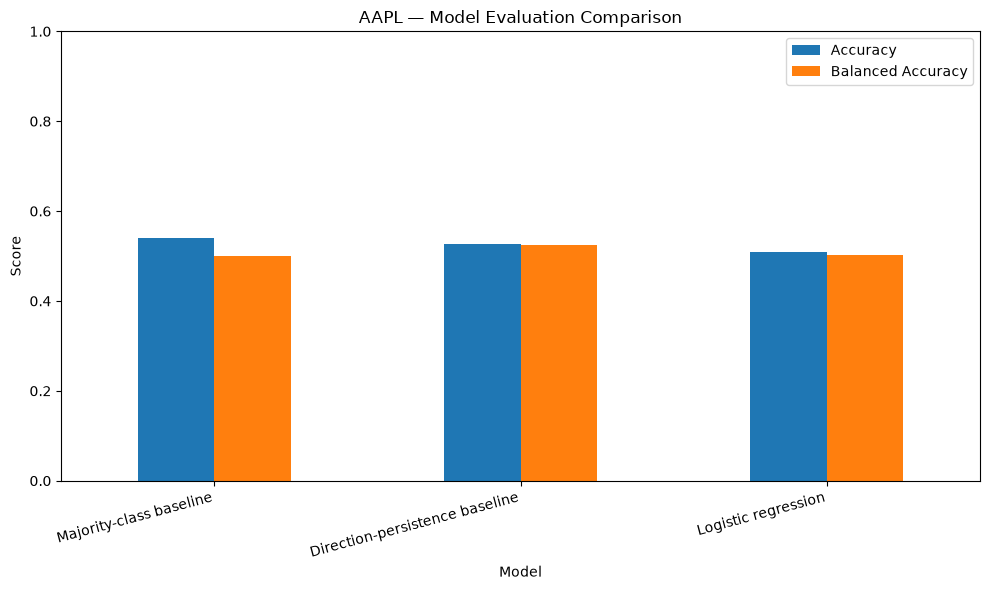

In [18]:
#Plotting the comparison of Accuracy and Balanced Accuracy 
comparison[["Accuracy", "Balanced Accuracy"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("AAPL — Model Evaluation Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [19]:
#Inspecting the confusion matrix for the logistic regression model
cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=[0, 1]
)

print("Rows = actual classes; columns = predicted classes")
print(cm)

Rows = actual classes; columns = predicted classes
[[ 97 139]
 [113 165]]


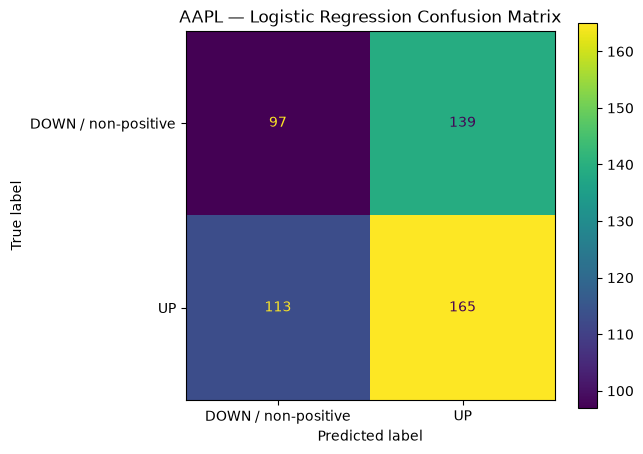

In [20]:
#Plotting the confusion matrix for the logistic regression model
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["DOWN / non-positive", "UP"]
).plot()

plt.title("AAPL — Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
# For labels ordered as [0, 1], the matrix is:
#                   Predicted
#                   0       1

# Actual 0         TN      FP
# Actual 1         FN      TP

In [22]:
#Printing the classification report for the logistic regression model    
print(
    classification_report(
        y_test,
        logistic_predictions,
        labels=[0, 1],
        target_names=["DOWN / non-positive", "UP"],
        zero_division=0
    )
)

                     precision    recall  f1-score   support

DOWN / non-positive       0.46      0.41      0.43       236
                 UP       0.54      0.59      0.57       278

           accuracy                           0.51       514
          macro avg       0.50      0.50      0.50       514
       weighted avg       0.51      0.51      0.51       514



In [24]:
#Creating a diagnostics DataFrame to analyze the model's predictions in detail    
diagnostics = pd.DataFrame({
    "actual_target": y_test,
    "predicted_target": pd.Series(
        logistic_predictions,
        index=test.index
    ),
    "probability_up": pd.Series(
        probability_up,
        index=test.index
    ),
    "actual_future_return": test["future_return_1d"]
}, index=test.index)

diagnostics["actual_direction"] = (
    diagnostics["actual_target"]
    .map({0: "DOWN / non-positive", 1: "UP"})
)

diagnostics["predicted_direction"] = (
    diagnostics["predicted_target"]
    .map({0: "DOWN / non-positive", 1: "UP"})
)

diagnostics["correct"] = (
    diagnostics["actual_target"] == diagnostics["predicted_target"]
)

diagnostics.tail(5)

,actual_target,predicted_target,probability_up,actual_future_return,actual_direction,predicted_direction,correct
Date,,,,,,,
2025-12-23 00:00:00-05:00,1,0,0.477348,0.005324,UP,DOWN / non-positive,False
2025-12-24 00:00:00-05:00,0,0,0.479677,-0.001497,DOWN / non-positive,DOWN / non-positive,True
2025-12-26 00:00:00-05:00,1,0,0.475914,0.001317,UP,DOWN / non-positive,False
2025-12-29 00:00:00-05:00,0,0,0.482498,-0.002484,DOWN / non-positive,DOWN / non-positive,True
2025-12-30 00:00:00-05:00,0,0,0.495682,-0.004468,DOWN / non-positive,DOWN / non-positive,True


In [25]:
#Displaying Incorrect Predictions with their error types
diagnostics["error_type"] = np.select(
    [
        (diagnostics["actual_target"] == 0) &
        (diagnostics["predicted_target"] == 1),

        (diagnostics["actual_target"] == 1) &
        (diagnostics["predicted_target"] == 0)
    ],
    [
        "False positive: predicted UP incorrectly",
        "False negative: missed an UP day"
    ],
    default="Correct"
)

misclassified = diagnostics.loc[
    ~diagnostics["correct"]
].sort_values(
    "probability_up",
    ascending=False
)

misclassified[
    [
        "actual_direction",
        "predicted_direction",
        "probability_up",
        "actual_future_return",
        "error_type"
    ]
].head(20)

,actual_direction,predicted_direction,probability_up,actual_future_return,error_type
Date,,,,,
2025-04-04 00:00:00-04:00,DOWN / non-positive,UP,0.771257,-0.036735,False positive: predicted UP incorrectly
2025-04-07 00:00:00-04:00,DOWN / non-positive,UP,0.739449,-0.049818,False positive: predicted UP incorrectly
2025-04-03 00:00:00-04:00,DOWN / non-positive,UP,0.672335,-0.072887,False positive: predicted UP incorrectly
2025-05-05 00:00:00-04:00,DOWN / non-positive,UP,0.651358,-0.001911,False positive: predicted UP incorrectly
2025-04-15 00:00:00-04:00,DOWN / non-positive,UP,0.650942,-0.038933,False positive: predicted UP incorrectly
2025-01-22 00:00:00-05:00,DOWN / non-positive,UP,0.636281,-0.000760,False positive: predicted UP incorrectly
2025-03-19 00:00:00-04:00,DOWN / non-positive,UP,0.631744,-0.005296,False positive: predicted UP incorrectly
2025-04-17 00:00:00-04:00,DOWN / non-positive,UP,0.629767,-0.019393,False positive: predicted UP incorrectly
2025-03-17 00:00:00-04:00,DOWN / non-positive,UP,0.629215,-0.006122,False positive: predicted UP incorrectly


In [30]:
print(type(diagnostics.index))
print(diagnostics.index[:5])

diagnostics.index = pd.to_datetime(diagnostics.index, utc=True)

<class 'pandas.Index'>
Index(['2023-12-12 00:00:00-05:00', '2023-12-13 00:00:00-05:00',
       '2023-12-14 00:00:00-05:00', '2023-12-15 00:00:00-05:00',
       '2023-12-18 00:00:00-05:00'],
      dtype='str', name='Date')


In [32]:
#Annual test period diagnostics to analyze the model's performance over time
annual_rows = []

for year, group in diagnostics.groupby(diagnostics.index.year):
    actual = group["actual_target"]
    predicted = group["predicted_target"]

    annual_rows.append({
            "Year": year,
            "Observations": len(group),
            "Accuracy": accuracy_score(actual, predicted),
            "Balanced Accuracy": (
                balanced_accuracy_score(actual, predicted)
                if actual.nunique() == 2
                else np.nan
            ),
            "UP Recall": recall_score(
                actual, predicted, pos_label=1, zero_division=0
            )
        })
    
    annual_diagnostics = (
        pd.DataFrame(annual_rows)
        .set_index("Year")
    )

In [35]:
# Annual test period diagnostics

diagnostics.index = pd.to_datetime(
    diagnostics.index,
    utc=True,
    errors="coerce"
)

annual_rows = []

for year, group in diagnostics.groupby(diagnostics.index.year):
    actual = group["actual_target"]
    predicted = group["predicted_target"]

    # Keep all your remaining original calculations here
    accuracy = (actual == predicted).mean()

    true_positives = ((actual == 1) & (predicted == 1)).sum()
    false_positives = ((actual == 0) & (predicted == 1)).sum()
    false_negatives = ((actual == 1) & (predicted == 0)).sum()

    precision = (
        true_positives / (true_positives + false_positives)
        if (true_positives + false_positives) > 0
        else 0
    )

    recall = (
        true_positives / (true_positives + false_negatives)
        if (true_positives + false_negatives) > 0
        else 0
    )

    up_recall = recall

    annual_rows.append({
        "year": year,
        "observations": len(group),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "up_recall": up_recall
    })

annual_diagnostics = pd.DataFrame(annual_rows)
annual_diagnostics

,year,observations,accuracy,precision,recall,up_recall
0,2023,13,0.384615,0.363636,0.800000,0.800000
1,2024,252,0.472222,0.530612,0.549296,0.549296
2,2025,249,0.554217,0.568493,0.633588,0.633588
